<a href="https://colab.research.google.com/github/DaNa-cpu/abnormal-behavior-detection/blob/main/ped2_dataset_dataloader.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCSD Ped2 - Dataset & DataLoader + Transforms, si split-uri

**Impartirea datelor pe video :**
- **train**: 13 secvente din Train (doar comportament normal)
- **val**: 3 secvente din Train (normale, folosite pentru early stopping / monitorizarea loss-ului)
- **test**: cele 12 secvente oficiale din Test (normal + anormal, cu etichete la nivel de cadru)

In [11]:
import os, glob, random, subprocess, tarfile
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## 1. Descarcare si dezarhivare

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
DATA_DIR = "/content/data"
ARCHIVE = f"{DATA_DIR}/UCSD_Anomaly_Dataset.tar.gz"
URL = "http://www.svcl.ucsd.edu/projects/anomaly/UCSD_Anomaly_Dataset.tar.gz"
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.isdir(f"{DATA_DIR}/UCSD_Anomaly_Dataset.v1p2"):
    if not os.path.exists(ARCHIVE):
        subprocess.run(["wget", "-q", "-O", ARCHIVE, URL], check=True)
    with tarfile.open(ARCHIVE) as tar:
        tar.extractall(DATA_DIR)

PED2_ROOT = f"{DATA_DIR}/UCSD_Anomaly_Dataset.v1p2/UCSDped2"
print(os.listdir(PED2_ROOT))

['Train', 'Test', '.DS_Store', '._.DS_Store']


## 2. Indexarea cadrelor si a etichetelor
Fiecare esantion = (cale_imagine, eticheta, nume_video, index_cadru).
Eticheta la test: cadrul e anormal (1) daca masca de adnotare TestXXX_gt/NNN.bmp contine pixeli nenuli.

In [14]:
def list_train_samples(root):
    samples = []
    for vdir in sorted(glob.glob(os.path.join(root, "Train", "Train[0-9][0-9][0-9]"))):
        name = os.path.basename(vdir)
        frames = sorted(glob.glob(os.path.join(vdir, "*.tif")))
        samples += [(f, 0, name, i) for i, f in enumerate(frames)]
    return samples


def list_test_samples(root):
    samples = []
    for vdir in sorted(glob.glob(os.path.join(root, "Test", "Test[0-9][0-9][0-9]"))):
        name = os.path.basename(vdir)
        frames = sorted(glob.glob(os.path.join(vdir, "*.tif")))
        masks = sorted(glob.glob(os.path.join(vdir + "_gt", "*.bmp")))
        assert len(frames) == len(masks), f"{name}: {len(frames)} cadre vs {len(masks)} masti"
        for i, (f, m) in enumerate(zip(frames, masks)):
            label = int(np.array(Image.open(m).convert("L")).max() > 0)
            samples.append((f, label, name, i))
    return samples


def split_train_val(train_samples, n_val_videos=3, seed=SEED):
    "n_val_videos pentru validare, restul pentru antrenare."
    videos = sorted({s[2] for s in train_samples})
    rng = random.Random(seed)
    rng.shuffle(videos)
    val_videos = set(videos[:n_val_videos])
    train = [s for s in train_samples if s[2] not in val_videos]
    val = [s for s in train_samples if s[2] in val_videos]
    return train, val

## 3. Dataset + Transforms
Pre-procesare: grayscale -> redimensionare -> tensor in [0, 1].
Nu se foloseste augmentare deoarece modelul trebuie sa invete aspectul "normal" al scenei fixe.

In [15]:
IMG_H, IMG_W = 128, 128

def get_transform(img_size=(IMG_H, IMG_W)):
    return transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize(img_size),
        transforms.ToTensor(),
    ])


class UCSDPed2Frames(Dataset):
    "(imagine[1,H,W], eticheta, nume_video, index_cadru)"
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label, video, frame_idx = self.samples[idx]
        img = Image.open(path).convert("L")
        if self.transform is not None:
            img = self.transform(img)
        return img, label, video, frame_idx

## 4. Construirea split-urilor si a DataLoader-elor

In [16]:
BATCH_SIZE = 64
NUM_WORKERS = 2

train_all = list_train_samples(PED2_ROOT)
test_samples = list_test_samples(PED2_ROOT)
train_samples, val_samples = split_train_val(train_all, n_val_videos=3)

tf = get_transform()
train_ds = UCSDPed2Frames(train_samples, tf)
val_ds = UCSDPed2Frames(val_samples, tf)
test_ds = UCSDPed2Frames(test_samples, tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

## 5. Verificari

In [17]:
def summarize(name, ds):
    labels = np.array([s[1] for s in ds.samples])
    videos = sorted({s[2] for s in ds.samples})
    print(f"{name:5s}: {len(ds):5d} cadre | {len(videos):2d} video | "
          f"normale={int((labels == 0).sum())}, anormale={int((labels == 1).sum())}")

summarize("train", train_ds); summarize("val", val_ds); summarize("test", test_ds)
print("Video train:", sorted({s[2] for s in train_samples}))
print("Video val  :", sorted({s[2] for s in val_samples}))

assert not ({s[2] for s in train_samples} & {s[2] for s in val_samples})
assert len({s[2] for s in train_all}) == 16, "Ped2 ar trebui sa aiba 16 secvente de antrenare"
assert len({s[2] for s in test_samples}) == 12, "Ped2 ar trebui sa aiba 12 secvente de test"

imgs, labels, videos, fidx = next(iter(train_loader))
print("Batch:", imgs.shape, imgs.dtype, f"min={imgs.min():.3f} max={imgs.max():.3f}")

train:  2100 cadre | 13 video | normale=2100, anormale=0
val  :   450 cadre |  3 video | normale=450, anormale=0
test :  2010 cadre | 12 video | normale=362, anormale=1648
Video train: ['Train001', 'Train002', 'Train003', 'Train004', 'Train005', 'Train007', 'Train009', 'Train011', 'Train012', 'Train013', 'Train014', 'Train015', 'Train016']
Video val  : ['Train006', 'Train008', 'Train010']


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch: torch.Size([64, 1, 128, 128]) torch.float32 min=0.137 max=0.737


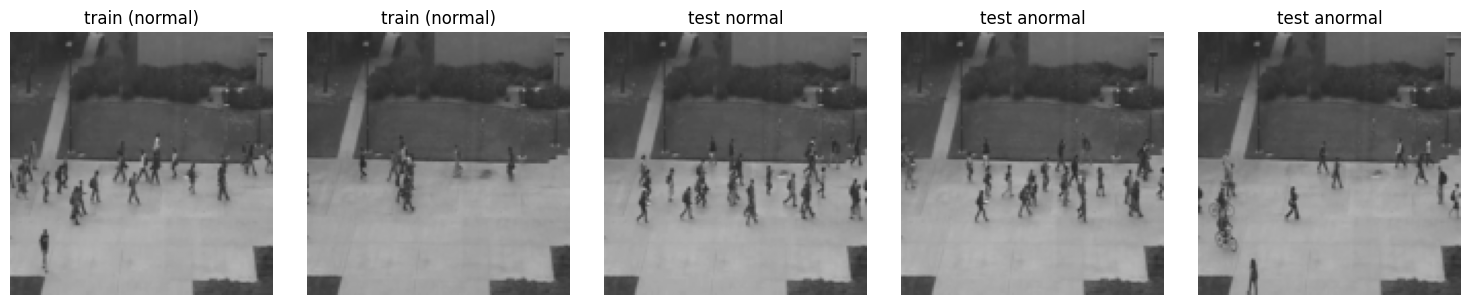

In [18]:
# Vizualizare: cadre normale (train) si cadre anormale (test)
anom = [i for i, s in enumerate(test_ds.samples) if s[1] == 1]
norm = [i for i, s in enumerate(test_ds.samples) if s[1] == 0]
picks = [("train (normal)", train_ds[0][0]), ("train (normal)", train_ds[len(train_ds) // 2][0]),
         ("test normal", test_ds[norm[0]][0]), ("test anormal", test_ds[anom[0]][0]),
         ("test anormal", test_ds[anom[len(anom) // 2]][0])]
fig, axes = plt.subplots(1, len(picks), figsize=(3 * len(picks), 3))
for ax, (title, im) in zip(axes, picks):
    ax.imshow(im.squeeze(0), cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()